# Laboratorio 21. Series de tiempo con datos simulados

**Asignatura:** Analítica de Datos  
**Docente:** Luis Miguel Gómez Meneses  
**Universidad Cooperativa de Colombia**  
**Programa:** Ingeniería de Software  
**Duración sugerida:** 25–30 minutos

## Objetivo

Reconocer tendencia y estacionalidad, suavizar una serie mediante promedios
móviles y evaluar pronósticos conservando el orden temporal.

### Situación de estudio

Una tienda registra sus ventas mensuales. Simularemos **60 meses**, de enero
de 2021 a diciembre de 2025, para responder:

> ¿Qué patrones presentan las ventas y qué tan bien funcionan algunas
> reglas sencillas para pronosticar el año siguiente?

**Todos los datos son ficticios.** Se generan dentro del notebook con NumPy.
No necesitas descargar una base de datos ni cargar archivos.

### Cómo trabajar

Ejecuta las celdas en orden, de arriba hacia abajo, y responde las preguntas
en las celdas Markdown. El código está completo y puedes usarlo en Google
Colab o Jupyter con Python 3.


## 1. Importación de librerías

Todas las importaciones están en esta celda:

- **NumPy:** generar datos reproducibles y calcular errores.
- **pandas:** organizar fechas y tablas, y calcular promedios móviles.
- **Matplotlib:** representar las series y los pronósticos.
- **display:** mostrar tablas en el notebook.

Estas librerías están disponibles habitualmente en Google Colab. En una
instalación local que no las tenga, instala `numpy`, `pandas`, `matplotlib`
e `ipython` antes de ejecutar el notebook.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# Presentación de tablas y gráficas.
pd.set_option('display.max_columns', 10)
plt.rcParams.update({
    'figure.figsize': (12, 4),
    'figure.dpi': 110,
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.20,
})

print('Librerías listas.')


Librerías listas.


## 2. Generación de las ventas mensuales

Construiremos la serie sumando tres componentes:

$$y_t = T_t + S_t + R_t$$

- **Tendencia:** comienza en 100 unidades y aumenta 0,8 unidades cada mes.
- **Estacionalidad:** un patrón que se repite cada 12 meses, con amplitud
  de 25 unidades. Usamos un coseno para producir esa repetición y ubicar
  el máximo estacional en diciembre.
- **Ruido:** variación aleatoria normal con media 0 y desviación estándar 4.

La semilla `42` permite repetir la simulación en el mismo entorno.
Redondeamos las ventas al entero más cercano para representar unidades.
La ecuación anterior se aplica antes de ese redondeo.

**Importante:** conocemos los componentes porque nosotros los generamos.
No estamos estimando una descomposición a partir de datos reales.


In [2]:
semilla = 42
n_meses = 60
rng = np.random.default_rng(semilla)

fechas = pd.date_range(start='2021-01-01', periods=n_meses, freq='MS')
t = np.arange(n_meses)

tendencia = 100 + 0.8 * t
estacionalidad = 25 * np.cos(2 * np.pi * (t - 11) / 12)
ruido = rng.normal(loc=0, scale=4, size=n_meses)
ventas = np.rint(tendencia + estacionalidad + ruido).astype(int)

datos = pd.DataFrame({
    'ventas': ventas,
    'tendencia_simulada': tendencia,
    'estacionalidad_simulada': estacionalidad,
    'ruido_simulado': ruido,
}, index=fechas)
datos.index.name = 'fecha'

print('Número de meses:', len(datos))
print('Inicio:', datos.index.min().strftime('%Y-%m'))
print('Final:', datos.index.max().strftime('%Y-%m'))
print('Valores faltantes:', int(datos.isna().sum().sum()))
display(datos.head(6).round(2))


Número de meses: 60
Inicio: 2021-01
Final: 2025-12
Valores faltantes: 0


,ventas,tendencia_simulada,estacionalidad_simulada,ruido_simulado
fecha,,,,
2021-01-01,123,100.0,21.65,1.22
2021-02-01,109,100.8,12.50,-4.16
2021-03-01,105,101.6,-0.00,3.00
2021-04-01,94,102.4,-12.50,3.76
2021-05-01,74,103.2,-21.65,-7.80
2021-06-01,74,104.0,-25.00,-5.21


### Preguntas 1 y 2

1. ¿Qué representa una fila de esta tabla y cuál es la frecuencia de la serie?
2. ¿Por qué las ventas pueden disminuir de un mes al siguiente aunque la
   tendencia simulada sea creciente?

**Respuestas:**

1. Escribe aquí.
2. Escribe aquí.


## 3. Separación temporal de los datos

Reservaremos los últimos 12 meses para evaluar los pronósticos:

| Conjunto | Fechas | Meses | Uso |
|---|---|---:|---|
| Entrenamiento | Enero de 2021 a diciembre de 2024 | 48 | Explorar patrones y calcular los pronósticos |
| Prueba | Enero a diciembre de 2025 | 12 | Medir los errores finales |

La separación equivale al 80 % y 20 %, **conservando el orden temporal**.
El análisis previo usará únicamente el entrenamiento.

Nos situaremos al cierre de diciembre de 2024 y pronosticaremos todo 2025
desde ese único momento. Los componentes simulados ayudan a explicar los
datos, pero los métodos de pronóstico utilizarán solo las ventas históricas.


In [3]:
horizonte = 12

entrenamiento = datos.iloc[:-horizonte].copy()
prueba = datos.iloc[-horizonte:].copy()
serie_train = entrenamiento['ventas']

resumen = pd.DataFrame({
    'conjunto': ['Entrenamiento', 'Prueba'],
    'meses': [len(entrenamiento), len(prueba)],
    'inicio': [entrenamiento.index.min().strftime('%Y-%m'),
               prueba.index.min().strftime('%Y-%m')],
    'final': [entrenamiento.index.max().strftime('%Y-%m'),
              prueba.index.max().strftime('%Y-%m')],
})

display(resumen)


,conjunto,meses,inicio,final
0,Entrenamiento,48,2021-01,2024-12
1,Prueba,12,2025-01,2025-12


## 4. Visualización de la serie y sus componentes

Observaremos solo los primeros cuatro años. La primera gráfica combina las
ventas y la tendencia conocida. Las otras muestran la estacionalidad y el ruido.

Los valores negativos de estacionalidad o ruido representan una contribución
que reduce las ventas respecto a la tendencia; no son ventas negativas.


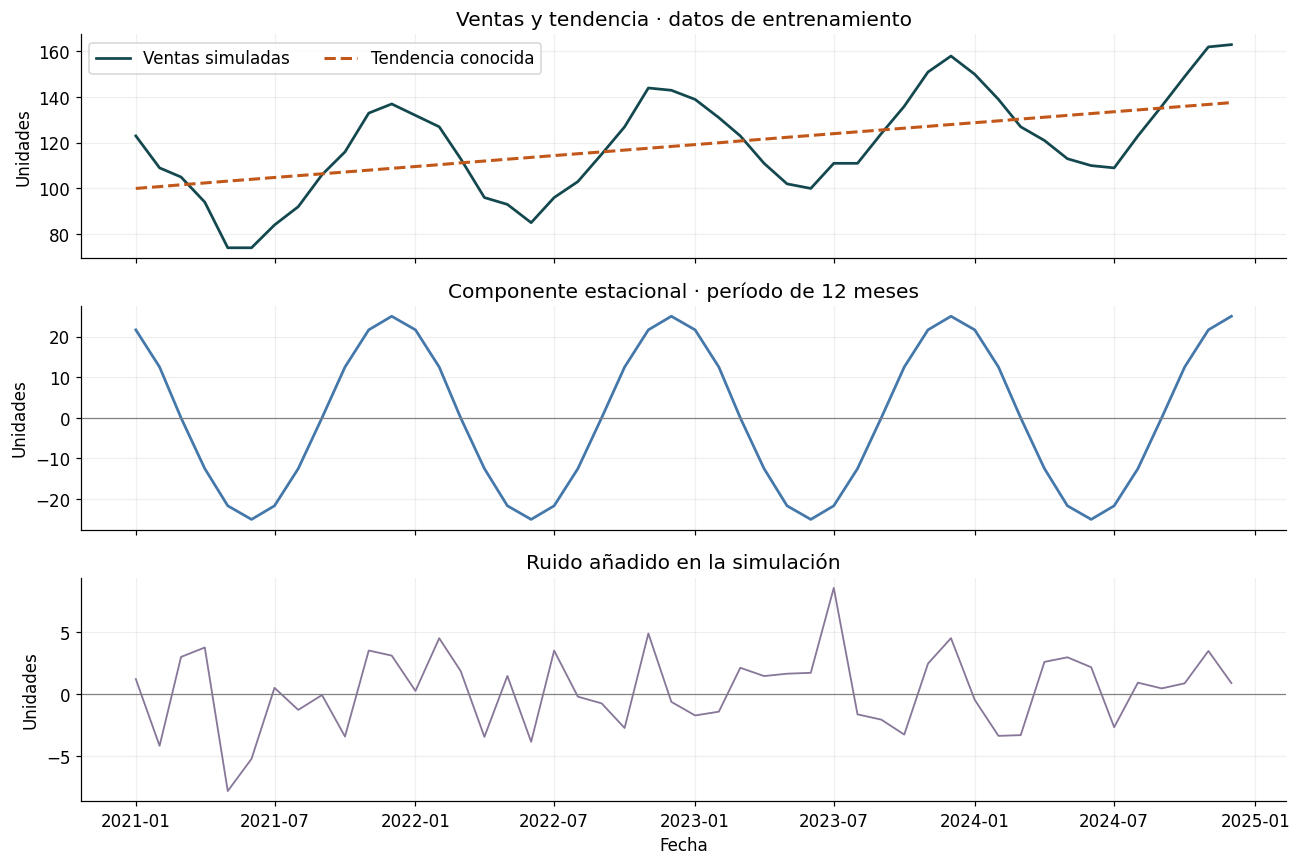

In [4]:
fig, ejes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

ejes[0].plot(serie_train.index, serie_train,
             color='#14484F', linewidth=1.8, label='Ventas simuladas')
ejes[0].plot(entrenamiento.index, entrenamiento['tendencia_simulada'],
             color='#C2571A', linestyle='--', linewidth=2,
             label='Tendencia conocida')
ejes[0].set_title('Ventas y tendencia · datos de entrenamiento')
ejes[0].set_ylabel('Unidades')
ejes[0].legend(loc='upper left', ncol=2)

ejes[1].plot(entrenamiento.index, entrenamiento['estacionalidad_simulada'],
             color='#4477AA', linewidth=1.8)
ejes[1].axhline(0, color='gray', linewidth=0.8)
ejes[1].set_title('Componente estacional · período de 12 meses')
ejes[1].set_ylabel('Unidades')

ejes[2].plot(entrenamiento.index, entrenamiento['ruido_simulado'],
             color='#887799', linewidth=1.2)
ejes[2].axhline(0, color='gray', linewidth=0.8)
ejes[2].set_title('Ruido añadido en la simulación')
ejes[2].set_ylabel('Unidades')
ejes[2].set_xlabel('Fecha')

fig.tight_layout()
plt.show()


### Preguntas 3 y 4

3. ¿Qué evidencia visual permite distinguir la tendencia de la estacionalidad?
4. ¿Por qué conocemos exactamente estos componentes en la simulación,
   pero no los conoceríamos directamente al recibir ventas reales?

**Respuestas:**

3. Escribe aquí.
4. Escribe aquí.


## 5. Promedio móvil de tres meses

El promedio móvil retrospectivo resume el mes actual y los dos anteriores:

$$M_t = \frac{y_t + y_{t-1} + y_{t-2}}{3}$$

El suavizado puede ayudar a reconocer el comportamiento general. También
puede reaccionar con retraso frente a subidas o caídas.

Los dos primeros resultados serán `NaN`: todavía no hay tres observaciones
para completar la ventana. **Las ventas originales no tienen datos faltantes.**

Esta curva describe datos observados. Por incluir el valor del mes actual,
no debe tratarse como un pronóstico de ese mismo mes.


,ventas,promedio_movil_3
fecha,,
2021-01-01,123,NaN
2021-02-01,109,NaN
2021-03-01,105,112.33
2021-04-01,94,102.67
2021-05-01,74,91.00
2021-06-01,74,80.67


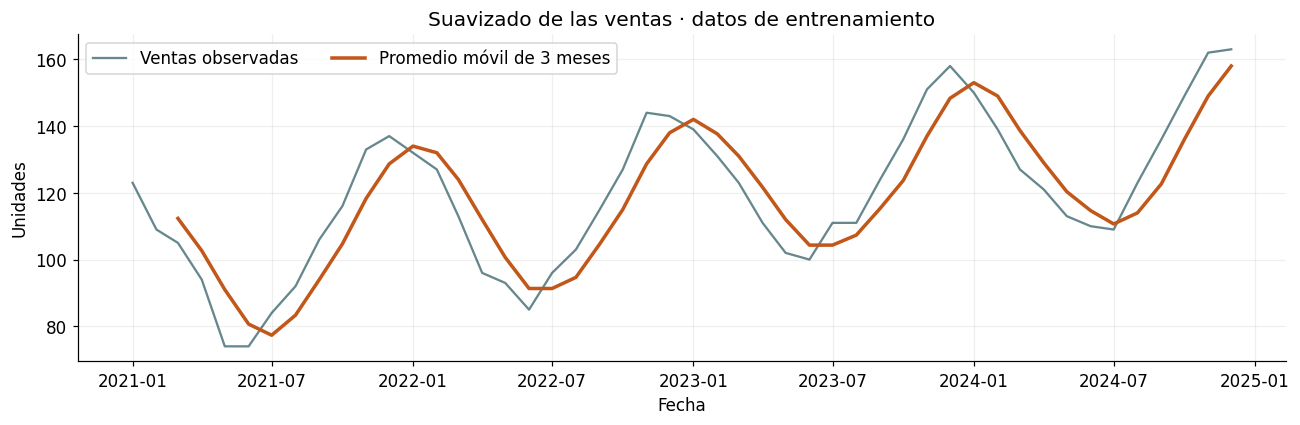

In [5]:
ventana = 3
promedio_movil = serie_train.rolling(window=ventana, min_periods=ventana).mean()

tabla_suavizado = pd.DataFrame({
    'ventas': serie_train,
    'promedio_movil_3': promedio_movil,
})
display(tabla_suavizado.head(6).round(2))

fig, ax = plt.subplots()
ax.plot(serie_train.index, serie_train,
        color='#14484F', alpha=0.65, label='Ventas observadas')
ax.plot(promedio_movil.index, promedio_movil,
        color='#C2571A', linewidth=2.3, label='Promedio móvil de 3 meses')
ax.set_title('Suavizado de las ventas · datos de entrenamiento')
ax.set_xlabel('Fecha')
ax.set_ylabel('Unidades')
ax.legend(loc='upper left', ncol=2)
fig.tight_layout()
plt.show()


### Pregunta 5

5. Observa una subida pronunciada. ¿Cómo responde el promedio móvil respecto
   a las ventas? Explica por qué no coincide exactamente con ellas.

**Respuesta:** Escribe aquí.


## 6. Pronósticos para los 12 meses de prueba

Compararemos tres reglas definidas antes de evaluar sus resultados:

| Método | Cálculo desde diciembre de 2024 |
|---|---|
| Ingenuo | Repetir la última venta conocida en los 12 meses futuros. |
| Media reciente (3 meses) | Repetir el promedio de octubre, noviembre y diciembre de 2024. |
| Ingenuo estacional | Usar para cada mes de 2025 la venta del mismo mes de 2024. |

Las dos primeras reglas generan valores constantes. La tercera conserva el
patrón del último año, aunque no incorpora explícitamente el crecimiento.

**El horizonte es de 12 meses y el período estacional también es de 12.**
Esto permite copiar, en orden, los últimos 12 valores históricos.

Ningún método se actualiza con las ventas reales de 2025. Utilizamos las
fechas de prueba como etiquetas, pero todavía no sus valores para pronosticar.


In [6]:
pronosticos = pd.DataFrame(index=prueba.index)

pronosticos['Ingenuo'] = np.repeat(serie_train.iloc[-1], horizonte)
pronosticos['Media reciente (3 meses)'] = np.repeat(
    serie_train.tail(ventana).mean(), horizonte
)
pronosticos['Ingenuo estacional'] = serie_train.iloc[-12:].to_numpy()

print('Origen de todos los pronósticos:', serie_train.index[-1].strftime('%Y-%m'))
print('Última venta conocida:', serie_train.iloc[-1])
print('Promedio de los últimos 3 meses:', round(serie_train.tail(ventana).mean(), 2))
display(pronosticos.round(2))


Origen de todos los pronósticos: 2024-12
Última venta conocida: 163
Promedio de los últimos 3 meses: 158.0


,Ingenuo,Media reciente (3 meses),Ingenuo estacional
fecha,,,
2025-01-01,163,158.0,150
2025-02-01,163,158.0,139
2025-03-01,163,158.0,127
2025-04-01,163,158.0,121
2025-05-01,163,158.0,113
2025-06-01,163,158.0,110
2025-07-01,163,158.0,109
2025-08-01,163,158.0,123
2025-09-01,163,158.0,136


### Pregunta 6 · Antes de evaluar

6. ¿Qué método esperas que represente mejor el patrón anual y por qué?
   ¿Qué limitación tendrá si el nivel de ventas sigue aumentando?

**Respuesta:** Escribe aquí antes de ejecutar la siguiente celda de código.


## 7. Evaluación con MAE y RMSE

Ahora comparamos cada pronóstico con las ventas reales simuladas de 2025.

$$\operatorname{MAE}=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|$$

$$\operatorname{RMSE}=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}$$

- **MAE:** promedio del tamaño de los errores, sin considerar su signo.
- **RMSE:** da mayor peso a los errores grandes por elevarlos al cuadrado.

Ambas métricas se expresan en **unidades vendidas**. Valores menores indican
menor error al comparar estos métodos sobre las mismas fechas.

Reportaremos los tres métodos. No ajustaremos sus parámetros utilizando la
prueba; para hacerlo necesitaríamos validación temporal dentro del historial.


In [7]:
resultados = []
valores_reales = prueba['ventas'].to_numpy()

for metodo in pronosticos.columns:
    valores_predichos = pronosticos[metodo].to_numpy()
    errores = valores_reales - valores_predichos

    resultados.append({
        'metodo': metodo,
        'MAE': np.mean(np.abs(errores)),
        'RMSE': np.sqrt(np.mean(errores ** 2)),
    })

metricas = pd.DataFrame(resultados).set_index('metodo').sort_values('MAE')
print('Errores en los 12 meses de prueba, expresados en unidades:')
display(metricas.round(2))


Errores en los 12 meses de prueba, expresados en unidades:


,MAE,RMSE
metodo,,
Ingenuo estacional,9.42,10.39
Media reciente (3 meses),21.08,25.28
Ingenuo,22.75,28.55


## 8. Comparación visual con los valores reales

La línea negra representa lo que realmente ocurrió en la simulación.
Las líneas discontinuas muestran los pronósticos calculados desde diciembre
de 2024. La línea vertical marca el inicio de la prueba.

Mostraremos también la tabla mensual para relacionar los errores con la gráfica.


,ventas_reales,Ingenuo,Media reciente (3 meses),Ingenuo estacional
fecha,,,,
2025-01-01,163,163,158.0,150
2025-02-01,152,163,158.0,139
2025-03-01,141,163,158.0,127
2025-04-01,131,163,158.0,121
2025-05-01,114,163,158.0,113
2025-06-01,116,163,158.0,110
2025-07-01,120,163,158.0,109
2025-08-01,129,163,158.0,123
2025-09-01,144,163,158.0,136


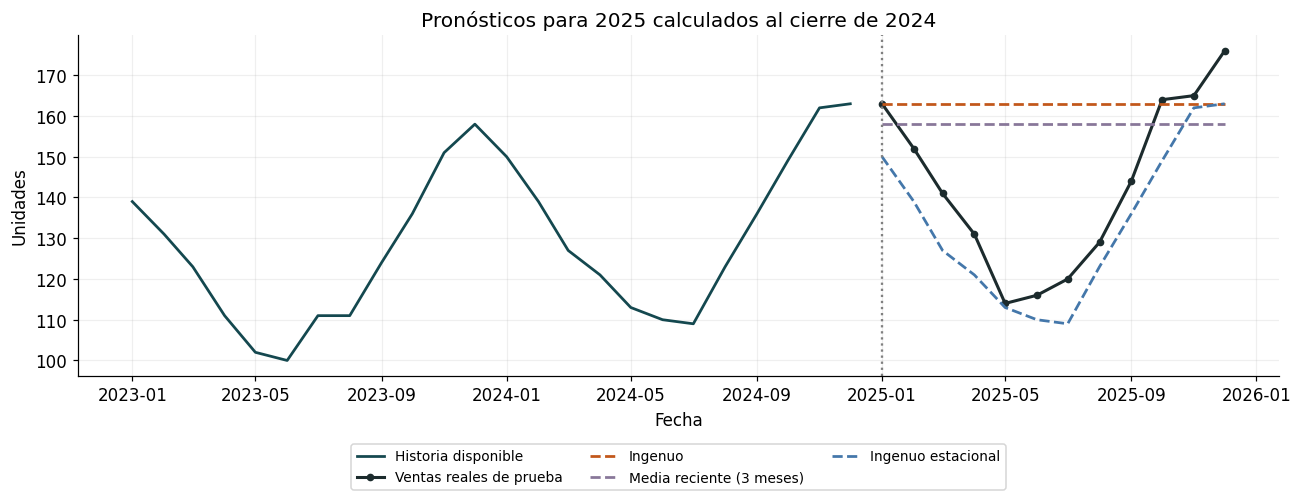

In [8]:
comparacion = pronosticos.copy()
comparacion.insert(0, 'ventas_reales', prueba['ventas'])
display(comparacion.round(2))

colores = {
    'Ingenuo': '#C2571A',
    'Media reciente (3 meses)': '#887799',
    'Ingenuo estacional': '#4477AA',
}

fig, ax = plt.subplots(figsize=(12, 4.8))
historia_reciente = serie_train.tail(24)
ax.plot(historia_reciente.index, historia_reciente,
        color='#14484F', label='Historia disponible', linewidth=1.8)
ax.plot(prueba.index, prueba['ventas'],
        color='#1C2B2D', marker='o', markersize=4,
        linewidth=2, label='Ventas reales de prueba')

for metodo in pronosticos.columns:
    ax.plot(pronosticos.index, pronosticos[metodo],
            color=colores[metodo], linestyle='--', linewidth=1.8, label=metodo)

ax.axvline(prueba.index[0], color='gray', linestyle=':', linewidth=1.5)
ax.set_title('Pronósticos para 2025 calculados al cierre de 2024')
ax.set_xlabel('Fecha')
ax.set_ylabel('Unidades')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=9)
fig.tight_layout()
plt.show()


### Preguntas 7 y 8

7. ¿Qué método obtuvo el menor MAE? Escribe su valor, interpreta sus unidades
   y relaciona el resultado con lo que observas en la gráfica.
8. ¿Por qué sería incorrecto utilizar ventas de 2025 para construir un
   pronóstico que afirmamos haber calculado en diciembre de 2024?

**Respuestas:**

7. Escribe aquí.
8. Escribe aquí.


## 9. Conclusión del laboratorio

Escribe una conclusión de **5 a 7 líneas** que conecte:

- La tendencia y la estacionalidad observadas.
- El propósito y la limitación del promedio móvil.
- El método con menor error en esta prueba, citando su MAE y RMSE.
- La importancia de conservar el orden temporal.

La comparación describe esta simulación y este período de prueba. Un método
con menor error aquí no tiene por qué ser el mejor para todas las series.

**Conclusión del estudiante:**

Escribe aquí tu conclusión.

---

**Entrega:** guarda este notebook con las celdas ejecutadas y las respuestas
completas. No necesitas archivos de datos adicionales.


## Referencias de apoyo

- Hyndman, R. J. y Athanasopoulos, G. *Forecasting: Principles and Practice*,
  tercera edición. [Patrones temporales](https://otexts.com/fpp3/graphics.html),
  [suavizado](https://otexts.com/fpp3/decomposition.html) y
  [pronósticos y evaluación](https://otexts.com/fpp3/toolbox.html).
- NumPy. [Generación de números aleatorios](https://numpy.org/doc/stable/reference/random/generator.html).
- pandas. [Ventanas móviles con `rolling`](https://pandas.pydata.org/docs/reference/api/pandas.Series.rolling.html).

Los datos y los ejemplos numéricos se generan expresamente para este laboratorio.
